# GSE129363: endothelial cells in adipose tissue

This notebook is a guided first analysis of the GSE129363 single-cell dataset. It compares the study's **Control** and **T2D** groups and keeps subcutaneous adipose tissue (**SAT**) separate from visceral adipose tissue (**VAT**).

We will use raw counts for clustering and donor-level pseudobulk tests. We will use the GEO normalized SVF file for expression plots of **ERG, PECAM1, CDH5, NOS3, VCAM1, ICAM1, HIF1A, and ANGPT2**.

Endothelial subtype names are provisional. Check the marker plots before treating them as final labels.

> **Display size:** diagrams are now shown at the same shape as the saved files and enlarged by `DISPLAY_SCALE` (set in the "save_plot" cell). Re-run the plotting cells to see the new sizes; the images already stored in this notebook keep their old size.


## Before you start

Put these five files in a folder called `data` beside this notebook. The files may be compressed with `.gz`. You may upload one ZIP file instead.

- `GSE129363_Discovery_Cohort_matrix.mtx`
- `GSE129363_Discovery_Cohort_genes.tsv`
- `GSE129363_Discovery_Cohort_barcodes.tsv`
- `GSE129363_Discovery_Cohort_CellAnnotation.txt`
- `GSE129363_SVF_Normalised_Data.txt`

In Jupyter, use the file browser to make the `data` folder and upload the files there.

## 1. Set up the project folders

This uses the folder where Jupyter is running, so it does not depend on one person's computer path.

In [1]:
project_dir <- getwd()
data_dir <- file.path(project_dir, "data")
results_dir <- file.path(project_dir, "results")

# Create the folders if they are not already there.
dir.create(data_dir, showWarnings = FALSE)
dir.create(file.path(results_dir, "plots"), recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(results_dir, "tables"), recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(results_dir, "DE"), recursive = TRUE, showWarnings = FALSE)

cat("Project folder:", project_dir, "\n")
cat("Upload data into:", data_dir, "\n")

Project folder: C:/Users/jovit/Downloads 
Upload data into: C:/Users/jovit/Downloads/data 


## 2. Install the packages

Run this section once on a new computer. It installs the R packages used below. If R says a package is locked or already in use, restart the R kernel and run this section again.

In [2]:
cran_packages <- c(
  "Seurat", "SeuratObject", "Matrix", "ggplot2", "dplyr", "tidyr",
  "ROCR", "fitdistrplus", "lmtest", "miniUI", "statmod"
)

missing_cran <- cran_packages[
  !vapply(cran_packages, requireNamespace, logical(1), quietly = TRUE)
]

if (length(missing_cran) > 0) {
  install.packages(
    missing_cran,
    repos = "https://cloud.r-project.org",
    dependencies = TRUE
  )
}

In [3]:
if (!requireNamespace("BiocManager", quietly = TRUE)) {
  install.packages("BiocManager", repos = "https://cloud.r-project.org")
}

bioc_packages <- c("edgeR", "limma")
missing_bioc <- bioc_packages[
  !vapply(bioc_packages, requireNamespace, logical(1), quietly = TRUE)
]

if (length(missing_bioc) > 0) {
  BiocManager::install(missing_bioc, ask = FALSE, update = FALSE)
}

## 3. Load packages and set analysis options

The packages are loaded here once. Later cells use the functions they provide.

In [4]:
suppressPackageStartupMessages({
  library(Seurat)
  library(SeuratObject)
  library(Matrix)
  library(ggplot2)
  library(dplyr)
  library(tidyr)
  library(edgeR)
  library(limma)
})

set.seed(1234)
min_cells_per_sample <- 5
min_donors_per_group <- 3
fdr_cutoff <- 0.05

cat("Seurat version:", as.character(packageVersion("Seurat")), "\n")
cat("R version:", R.version.string, "\n")

Warning message:
"package 'Seurat' was built under R version 4.2.3"
Warning message:
"package 'SeuratObject' was built under R version 4.2.3"
Warning message:
"package 'sp' was built under R version 4.2.3"
Warning message:
"package 'Matrix' was built under R version 4.2.3"
Warning message:
"package 'ggplot2' was built under R version 4.2.3"


Seurat version: 5.0.3 
R version: R version 4.2.2 (2022-10-31 ucrt) 


In [5]:
# Size of the diagrams shown on screen. The saved PNG files keep their own size (300 dpi).
# Make DISPLAY_SCALE bigger (for example 1.6) if you still want larger diagrams on screen.
DISPLAY_SCALE <- 1.3
show_plot <- function(plot, width = 10, height = 6) {
  options(repr.plot.width = width * DISPLAY_SCALE, repr.plot.height = height * DISPLAY_SCALE, repr.plot.res = 110)
  print(plot)
}

save_plot <- function(plot, name, width = 10, height = 6) {
  ggsave(
    file.path(results_dir, "plots", paste0(name, ".png")),
    plot, width = width, height = height, dpi = 300, bg = "white"
  )
}

save_table <- function(table, name, folder = "tables") {
  write.csv(
    table,
    file.path(results_dir, folder, name),
    row.names = FALSE
  )
}

## 4. Find the uploaded files

The helper below accepts ordinary files, `.gz` files, and common download names such as `file(1).gz`. It stops with a message if a required file is missing or duplicated.

In [6]:
uploaded_files <- list.files(
  data_dir,
  recursive = TRUE,
  full.names = TRUE
)

zip_files <- uploaded_files[grepl("\\.zip$", uploaded_files, ignore.case = TRUE)]
count_matrix_name <- "GSE129363_Discovery_Cohort_matrix.mtx"
has_count_matrix <- any(grepl(count_matrix_name, basename(uploaded_files), fixed = TRUE))

In [7]:
# Unpack one ZIP if the count matrix is not already in the data folder.
input_dir <- data_dir

if (!has_count_matrix && length(zip_files) == 1) {
  input_dir <- file.path(data_dir, "unzipped")
  dir.create(input_dir, showWarnings = FALSE)
  unzip(zip_files[1], exdir = input_dir)
}

if (!has_count_matrix && length(zip_files) > 1) {
  stop("Please upload the five files directly or upload one ZIP file.")
}

In [8]:
clean_file_name <- function(path) {
  name <- tolower(basename(path))
  name <- sub("\\.gz$", "", name)
  sub("\\([0-9]+\\)$", "", name)
}

find_uploaded_file <- function(expected_name) {
  files <- list.files(input_dir, recursive = TRUE, full.names = TRUE)
  matches <- files[clean_file_name(files) == clean_file_name(expected_name)]

  if (length(matches) != 1) {
    stop("Expected one file named ", expected_name,
         ". Files found: ", paste(basename(files), collapse = ", "))
  }
  matches[1]
}

In [9]:
matrix_file <- find_uploaded_file("GSE129363_Discovery_Cohort_matrix.mtx")
genes_file <- find_uploaded_file("GSE129363_Discovery_Cohort_genes.tsv")
barcodes_file <- find_uploaded_file("GSE129363_Discovery_Cohort_barcodes.tsv")
annotation_file <- find_uploaded_file("GSE129363_Discovery_Cohort_CellAnnotation.txt")
normalized_file <- find_uploaded_file("GSE129363_SVF_Normalised_Data.txt")

cat("Found all five input files.\n")

Found all five input files.


## 5. Read the input data

The count matrix is sparse, so it can be read without turning all its zero values into a large dense table. A small helper opens either a text file or a compressed text file.

In [10]:
open_text_file <- function(path) {
  if (grepl("\\.gz$", path, ignore.case = TRUE)) {
    gzfile(path, open = "rt")
  } else {
    file(path, open = "rt")
  }
}

read_uploaded_file <- function(path, reader, ...) {
  connection <- open_text_file(path)
  on.exit(close(connection))
  reader(connection, ...)
}

In [11]:
counts <- read_uploaded_file(matrix_file, Matrix::readMM)
genes <- read_uploaded_file(
  genes_file, utils::read.delim,
  header = FALSE, stringsAsFactors = FALSE
)
barcodes <- read_uploaded_file(
  barcodes_file, utils::read.delim,
  header = FALSE, stringsAsFactors = FALSE
)[[1]]
annotation <- read_uploaded_file(
  annotation_file, utils::read.delim,
  stringsAsFactors = FALSE
)

cat("Raw matrix:", nrow(counts), "genes by", ncol(counts), "barcodes\n")
cat("Annotated rows:", nrow(annotation), "\n")
cat("Normalized SVF file:", basename(normalized_file), "\n")

Raw matrix: 33694 genes by 38170 barcodes
Annotated rows: 26350 
Normalized SVF file: GSE129363_SVF_Normalised_Data.txt.gz 


In [12]:
# Check the annotation columns before using them below.
print(names(annotation))
print(head(annotation))
print(unique(annotation$Condition))
print(unique(annotation$Tissue))

[1] "CellID"     "SampleName" "Condition"  "Tissue"    
              CellID SampleName Condition Tissue
1 AAACCTGAGCCATCGC-1   SVF2-SAT  Diabetic    SAT
2 AAACCTGAGGACCACA-1   SVF2-SAT  Diabetic    SAT
3 AAACCTGAGGGAGTAA-1   SVF2-SAT  Diabetic    SAT
4 AAACCTGCAGAGCCAA-1   SVF2-SAT  Diabetic    SAT
5 AAACCTGCATCACAAC-1   SVF2-SAT  Diabetic    SAT
6 AAACCTGGTGGGTCAA-1   SVF2-SAT  Diabetic    SAT
[1] "Diabetic"    "NonDiabetic"
[1] "SAT" "VAT"


## 6. Keep the author-annotated cells

The study files contain 38,170 barcodes. This notebook uses the cells listed in the authors' annotation file and leaves the other barcodes out of the main analysis, as requested.

In [13]:
cat("Barcodes in count file:", length(barcodes), "\n")
cat("Cells with author annotations:", length(unique(annotation$CellID)), "\n")
cat("Barcodes without an annotation:",
    sum(!barcodes %in% annotation$CellID), "\n")

stopifnot(all(annotation$CellID %in% barcodes))

Barcodes in count file: 38170 
Cells with author annotations: 26350 
Barcodes without an annotation: 11820 


In [14]:
# Add gene symbols and cell barcodes to the count matrix.
rownames(counts) <- make.unique(as.character(genes[[2]]))
colnames(counts) <- barcodes

# Keep only the annotated cells.
counts <- counts[, annotation$CellID, drop = FALSE]

cat("Annotated count matrix:", nrow(counts), "genes by", ncol(counts), "cells\n")

Annotated count matrix: 33694 genes by 26350 cells


In [15]:
# Prepare the sample information for each cell.
metadata <- data.frame(
  sample = annotation$SampleName,
  condition = annotation$Condition,
  tissue = annotation$Tissue,
  row.names = annotation$CellID
)

# Use simple names for the two comparison groups.
metadata$condition[metadata$condition == "NonDiabetic"] <- "Control"
metadata$condition[metadata$condition == "Diabetic"] <- "T2D"
metadata$donor <- sub("[-_](SAT|VAT)$", "", metadata$sample)
metadata$batch <- ifelse(grepl("^SVF", metadata$sample), "SVF", "Ate")

metadata$condition <- factor(metadata$condition, levels = c("Control", "T2D"))
metadata$tissue <- factor(metadata$tissue, levels = c("SAT", "VAT"))

print(table(metadata$condition, metadata$tissue))

         
           SAT  VAT
  Control 6360 8011
  T2D     7091 4888


## 7. Create the Seurat object

A Seurat object keeps the count matrix and the cell/sample information together.

In [16]:
obj <- CreateSeuratObject(
  counts = counts,
  meta.data = metadata
)

# Calculate the percentage of counts from mitochondrial genes.
obj[["percent.mt"]] <- PercentageFeatureSet(obj, pattern = "^MT-")

cat("Cells in Seurat object:", ncol(obj), "\n")

Warning message:
"Feature names cannot have underscores ('_'), replacing with dashes ('-')"
Warning message:
"Data is of class dgTMatrix. Coercing to dgCMatrix."


Cells in Seurat object: 26350 


## 8. Review quality-control measurements

The thresholds discussed for this dataset are more than 200 detected genes and less than 20% mitochondrial counts. This cell reports how many author-annotated cells meet them. It does not apply a second round of cell filtering.

In [17]:
obj$qc_pass <- obj$nFeature_RNA > 200 & obj$percent.mt < 20
print(table(obj$qc_pass, useNA = "ifany"))

qc_by_sample <- obj[[]] |>
  count(sample, condition, tissue, qc_pass, name = "n_cells")
print(qc_by_sample)


 TRUE 
26350 
       sample condition tissue qc_pass n_cells
1  Ate-04-SAT   Control    SAT    TRUE     411
2  Ate-04-VAT   Control    VAT    TRUE    2289
3  Ate-05-SAT       T2D    SAT    TRUE     174
4  Ate-05-VAT       T2D    VAT    TRUE    2243
5  Ate-06-SAT   Control    SAT    TRUE     664
6  Ate-06-VAT   Control    VAT    TRUE     250
7  Ate-08-SAT   Control    SAT    TRUE     473
8  Ate-08-VAT   Control    VAT    TRUE     849
9  Ate-09-SAT   Control    SAT    TRUE     663
10 Ate-09-VAT   Control    VAT    TRUE    1467
11 Ate-10-SAT       T2D    SAT    TRUE     210
12 Ate-10_VAT       T2D    VAT    TRUE     765
13 Ate-11-SAT   Control    SAT    TRUE     382
14 Ate-11-VAT   Control    VAT    TRUE    1462
15 Ate-12-SAT   Control    SAT    TRUE    2148
16 Ate-12-VAT   Control    VAT    TRUE     373
17 Ate-13-SAT       T2D    SAT    TRUE     861
18 Ate-13-VAT       T2D    VAT    TRUE     550
19 Ate-14-SAT   Control    SAT    TRUE     228
20 Ate-14-VAT   Control    VAT    TRUE     95

Warning message:
"Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead."


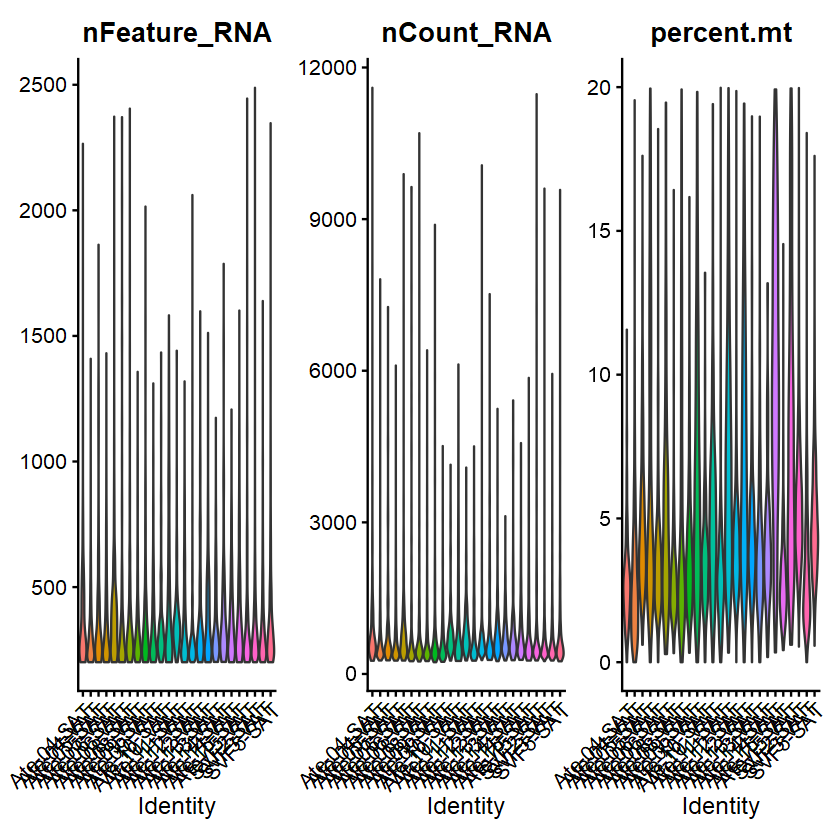

In [18]:
qc_plot <- VlnPlot(
  obj,
  features = c("nFeature_RNA", "nCount_RNA", "percent.mt"),
  group.by = "sample",
  pt.size = 0,
  ncol = 3
)
show_plot(qc_plot, 14, 6)
save_plot(qc_plot, "QC_metrics_by_sample", 14, 6)

## 9. Normalize and cluster the annotated cells

These steps make a low-dimensional map of the annotated cells. The labels from the study are still used as the starting point for deciding which cells are endothelial.

In [19]:
obj <- NormalizeData(obj)
obj <- FindVariableFeatures(obj, nfeatures = 2000)
obj <- ScaleData(obj)

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix



In [20]:
obj <- RunPCA(obj, npcs = 30, seed.use = 1234)
obj <- FindNeighbors(obj, dims = 1:20)
obj <- FindClusters(obj, resolution = 0.4, random.seed = 1234)

PC_ 1 
Positive:  MGP, ADIRF, ITLN1, C3, SLPI, KRT18, TIMP1, PLA2G2A, DCN, RARRES2 
	   TM4SF1, TPT1, KRT8, CLU, IGFBP6, KRT19, MSLN, CCL2, S100A10, TFPI2 
	   IFI27, MT1E, LUM, IGFBP5, OGN, CAV1, APOD, PRG4, MT1M, TPM2 
Negative:  TYROBP, FCER1G, CTSB, CXCL3, TREM2, HLA-DRA, LIPA, CCL3, CD74, C1QB 
	   CXCL8, CD68, SPP1, CTSD, FABP5, LYZ, FTL, FABP4, CSTB, CTSS 
	   ACP5, SRGN, AIF1, HLA-DRB1, C1QA, LAPTM5, CXCL2, APOC1, SH3BGRL3, ITGB2 
PC_ 2 
Positive:  S100A4, LUM, CFD, APOD, DCN, CXCL14, SERPINF1, GPX3, MFAP4, GSN 
	   NKG7, CCL5, DPT, MFAP5, IL32, COL6A3, CXCL12, GNLY, SRPX, CXCR4 
	   WISP2, KLRB1, MMP2, VIM, CST7, CD3D, IGFBP7, GZMB, PCOLCE, GZMH 
Negative:  ITLN1, KRT18, TM4SF1, KRT8, SLPI, KRT19, ADIRF, TIMP1, MSLN, TFPI2 
	   UPK3B, SAT1, EZR, HP, C3, MT1E, RARRES2, CALB2, TPM2, KLK11 
	   OGN, C19orf33, CLDN1, PRG4, CCL2, IFI27, CLDN15, MT-CO1, MT2A, CYSTM1 
PC_ 3 
Positive:  DCN, LUM, GSN, CFD, MGP, APOD, SERPINF1, CD63, CXCL14, S100A6 
	   LGALS1, VIM, IGFBP6, COL1A2, GPX

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 26350
Number of edges: 923582

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9261
Number of communities: 12
Elapsed time: 9 seconds


Warning message:
"The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session"
17:23:29 UMAP embedding parameters a = 0.9922 b = 1.112

17:23:29 Read 26350 rows and found 20 numeric columns

17:23:29 Using Annoy for neighbor search, n_neighbors = 30

17:23:29 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:23:36 Writing NN index file to temp file C:\Users\jovit\AppData\Local\Temp\Rtmpmcf6j7\file1b7c37106611

17:23:36 Searching Annoy index using 1 thread, search_k = 3000

17:23:52 Annoy recall = 100%

17:23:52 Commencing smooth kNN distance calibration using 1 thr

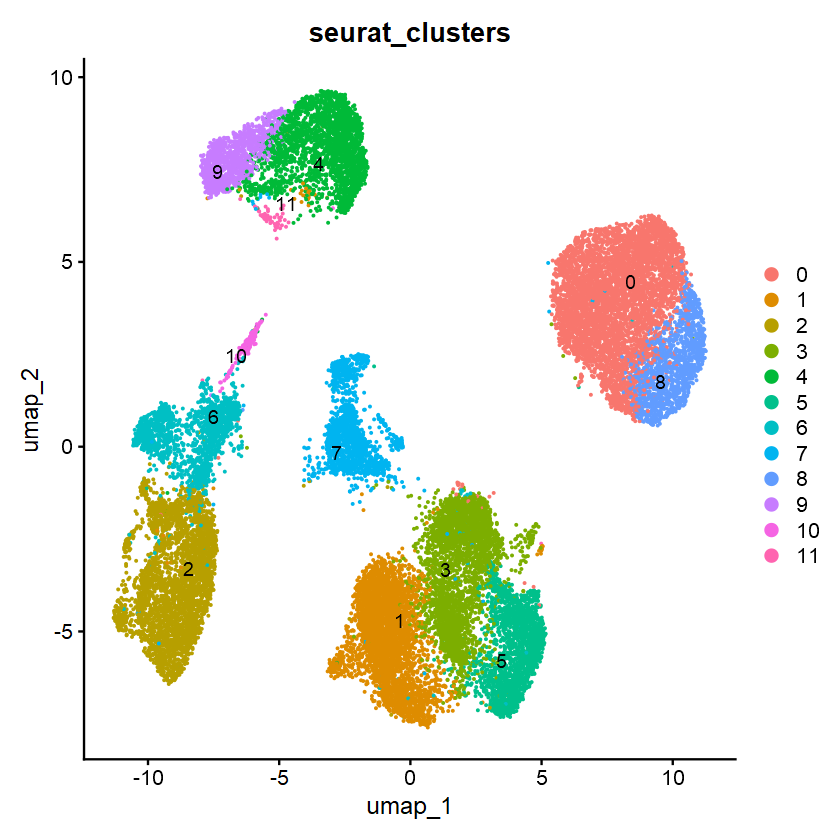

In [21]:
obj <- RunUMAP(obj, dims = 1:20, seed.use = 1234)

cluster_plot <- DimPlot(
  obj, reduction = "umap",
  group.by = "seurat_clusters",
  label = TRUE, repel = TRUE
)
show_plot(cluster_plot, 9, 7)
save_plot(cluster_plot, "All_cells_clusters_UMAP", 9, 7)

## 10. Review broad cell labels

The cluster-to-cell labels below are working labels from the current notebook. Use marker expression to review them; do not treat the cluster number alone as proof of cell identity.

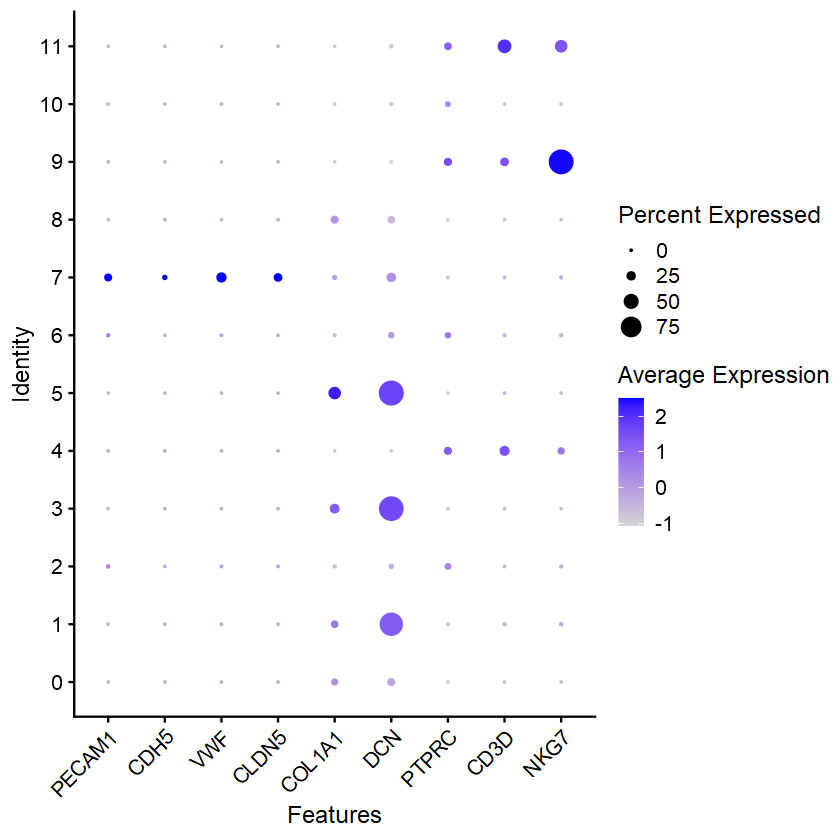

In [22]:
broad_markers <- c(
  "PECAM1", "CDH5", "VWF", "CLDN5",
  "COL1A1", "DCN", "PTPRC", "CD3D", "NKG7"
)
broad_markers <- intersect(broad_markers, rownames(obj))

broad_dotplot <- DotPlot(
  obj, features = broad_markers,
  group.by = "seurat_clusters"
) + RotatedAxis()
show_plot(broad_dotplot, 12, 6)
save_plot(broad_dotplot, "Broad_cluster_marker_dotplot", 12, 6)

In [23]:
cluster_labels <- c(
  "0" = "Mesothelial 1",
  "1" = "Macrophage",
  "2" = "Fibroblast / ASPC 1",
  "3" = "Fibroblast / ASPC 2",
  "4" = "Fibroblast / ASPC 3",
  "5" = "T cell",
  "6" = "Monocyte-associated",
  "7" = "Endothelial candidate",
  "8" = "Mesothelial 2",
  "9" = "NK cell",
  "10" = "T/NK-associated",
  "11" = "B cell",
  "12" = "Smooth muscle / pericyte"
)

obj$cell_type <- unname(cluster_labels[as.character(obj$seurat_clusters)])
print(table(obj$cell_type, useNA = "ifany"))


               B cell Endothelial candidate   Fibroblast / ASPC 1 
                   61                  1545                  3595 
  Fibroblast / ASPC 2   Fibroblast / ASPC 3            Macrophage 
                 3147                  2459                  3795 
        Mesothelial 1         Mesothelial 2   Monocyte-associated 
                 5252                  1449                  1700 
              NK cell                T cell       T/NK-associated 
                 1059                  2092                   196 


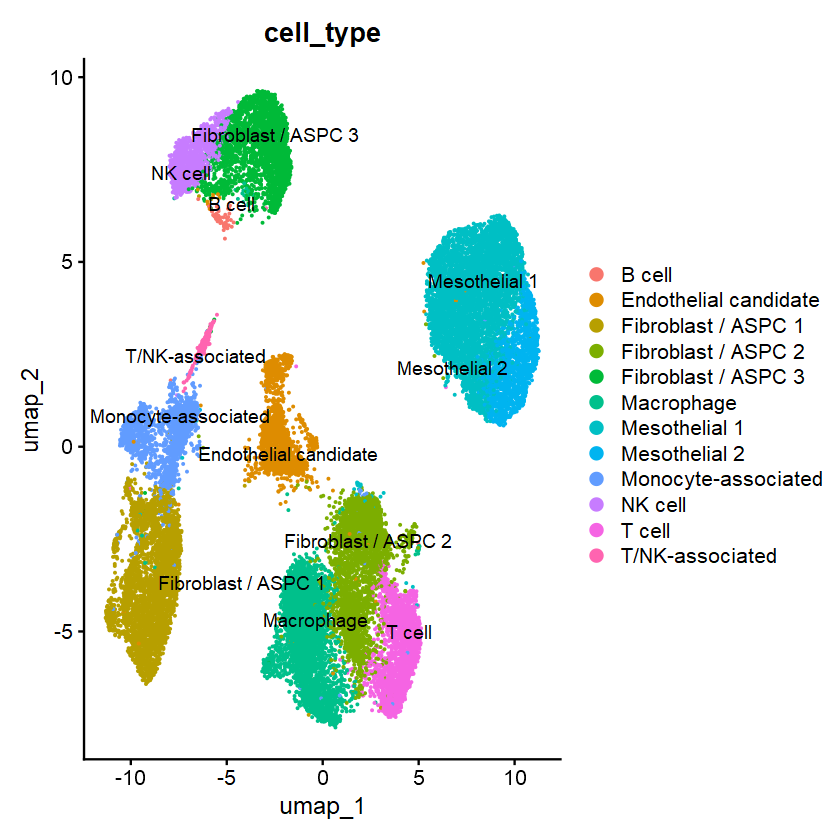

In [24]:
cell_type_plot <- DimPlot(
  obj, reduction = "umap",
  group.by = "cell_type",
  label = TRUE, repel = TRUE
)
show_plot(cell_type_plot, 11, 8)
save_plot(cell_type_plot, "All_cells_cell_type_UMAP", 11, 8)

## 11. Look at the eight target genes

This first view shows where the target genes appear across all annotated cells. Genes that are not present in the count matrix are listed so they are not mistaken for zero expression.

In [25]:
focus_genes <- c(
  "ERG", "PECAM1", "CDH5", "NOS3",
  "VCAM1", "ICAM1", "HIF1A", "ANGPT2"
)

found_focus_genes <- intersect(focus_genes, rownames(obj))
missing_focus_genes <- setdiff(focus_genes, found_focus_genes)
cat("Found:", paste(found_focus_genes, collapse = ", "), "\n")
cat("Not found:", paste(missing_focus_genes, collapse = ", "), "\n")

Found: ERG, PECAM1, CDH5, NOS3, VCAM1, ICAM1, HIF1A, ANGPT2 
Not found:  


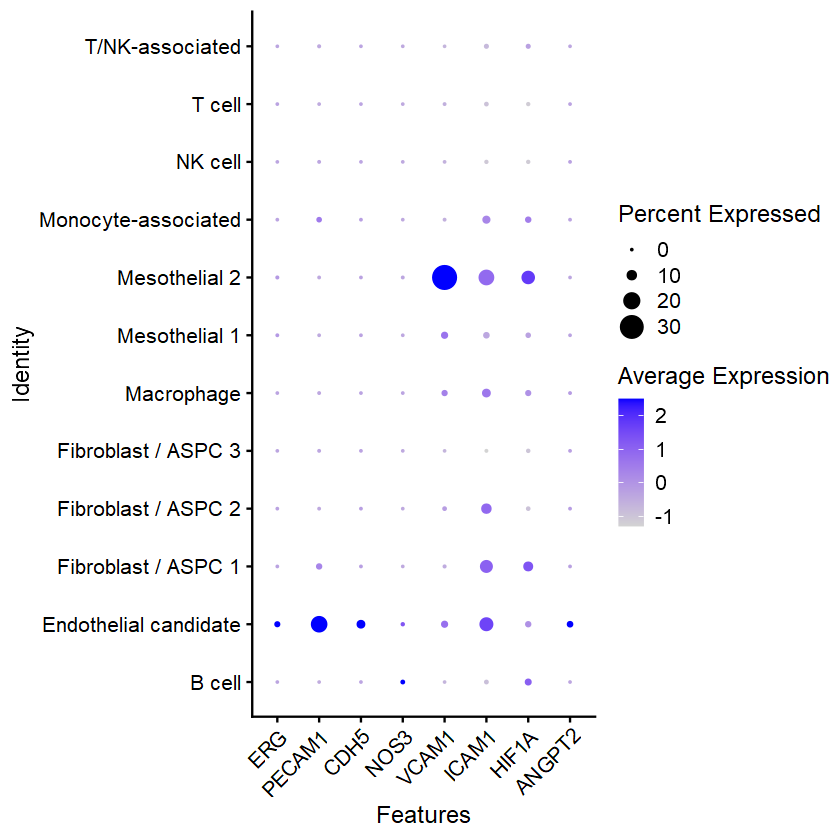

In [26]:
target_dotplot <- DotPlot(
  obj, features = found_focus_genes,
  group.by = "cell_type"
) + RotatedAxis()
show_plot(target_dotplot, 12, 6)
save_plot(target_dotplot, "Target_genes_by_broad_cell_type", 12, 6)

## 12. Subset and recluster endothelial candidates

The current broad-cell review identifies cluster 7 as the endothelial candidate group. This subset is reclustered so that endothelial subgroups can be reviewed separately.

In [27]:
endo <- subset(obj, subset = cell_type == "Endothelial candidate")
cat("Endothelial candidate cells:", ncol(endo), "\n")
print(table(endo$condition, endo$tissue))

Endothelial candidate cells: 1545 
         
          SAT VAT
  Control 566 252
  T2D     489 238


In [28]:
endo <- NormalizeData(endo)
endo <- FindVariableFeatures(endo, nfeatures = 2000)
endo <- ScaleData(endo)

Normalizing layer: counts

Finding variable features for layer counts

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
"pseudoinverse used at -2.8879"
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
"neighborhood radius 0.30103"
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
"reciprocal condition number  1.0922e-14"
Centering and scaling data matrix

Warning message:
"Different features in new layer data than already exists for scale.data"


In [29]:
endo <- RunPCA(endo, npcs = 20, seed.use = 1234)
endo <- FindNeighbors(endo, dims = 1:15)
endo <- FindClusters(endo, resolution = 0.3, random.seed = 1234)
endo$endo_cluster <- as.character(endo$seurat_clusters)

print(table(endo$endo_cluster))

PC_ 1 
Positive:  NFKBIA, RPS2, ACKR1, SELE, HLA-DRA, VIM, EMP1, HLA-DRB1, NPC2, CD74 
	   TFPI, CLU, JUNB, TM4SF1, FTH1, CST3, HLA-DPB1, ANXA2, LMNA, NEAT1 
	   ICAM1, ECSCR.1, BTG1, AQP1, ZFP36L2, HLA-DPA1, S100A10, CSF3, MMRN1, HLA-DMA 
Negative:  RERGL, ACTA2, TAGLN, TPM2, FABP4, MYH11, MT1M, MT1A, MYL9, PLN 
	   C12orf75, LMOD1, MT2A, CRIP1, CNN1, MT1G, DNAJC27, ITLN1, LBH, PTGDS 
	   SORBS2, TMEM150A, KLRB1, NDUFA4L2, C12orf45, COX4I2, MT1E, SLPI, CALD1, THBS1 
PC_ 2 
Positive:  TM4SF1, B2M, ACKR1, SELE, CD74, HLA-DRA, CSF3, CLU, HLA-DRB1, IL6 
	   PLVAP, VCAM1, ECSCR.1, ADAMTS9, HLA-DQA1, HLA-DPA1, AQP1, RAMP3, VWF, NPDC1 
	   IFI27, C2CD4B, SELP, IGFBP7, TSPAN7, STC1, RCAN1, HSPB1, RND1, NFKBIA 
Negative:  DCN, S100A4, MGP, LUM, APOD, COL1A2, SERPINF1, CXCL14, COL3A1, DPT 
	   COL6A2, CCDC80, MGST1, COL6A1, CFD, IGFBP5, IGFBP6, C3, C1S, COL1A1 
	   GPX3, ADH1B, FTL, COL6A3, GSN, C1R, RGS5, PTGDS, MFAP4, MMP2 
PC_ 3 
Positive:  TFF3, CCL21, ACTA2, RERGL, TAGLN, DSTN, TPM2, MYH11

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1545
Number of edges: 57011

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8503
Number of communities: 7
Elapsed time: 0 seconds

  0   1   2   3   4   5   6 
541 466 234  94  93  66  51 


17:25:30 UMAP embedding parameters a = 0.9922 b = 1.112

17:25:30 Read 1545 rows and found 15 numeric columns

17:25:30 Using Annoy for neighbor search, n_neighbors = 30

17:25:30 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:25:31 Writing NN index file to temp file C:\Users\jovit\AppData\Local\Temp\Rtmpmcf6j7\file1b7c737a7ed4

17:25:31 Searching Annoy index using 1 thread, search_k = 3000

17:25:32 Annoy recall = 100%

17:25:32 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

17:25:33 Initializing from normalized Laplacian + noise (using RSpectra)

17:25:33 Commencing optimization for 500 epochs, with 60064 positive edges

17:25:43 Optimization finished



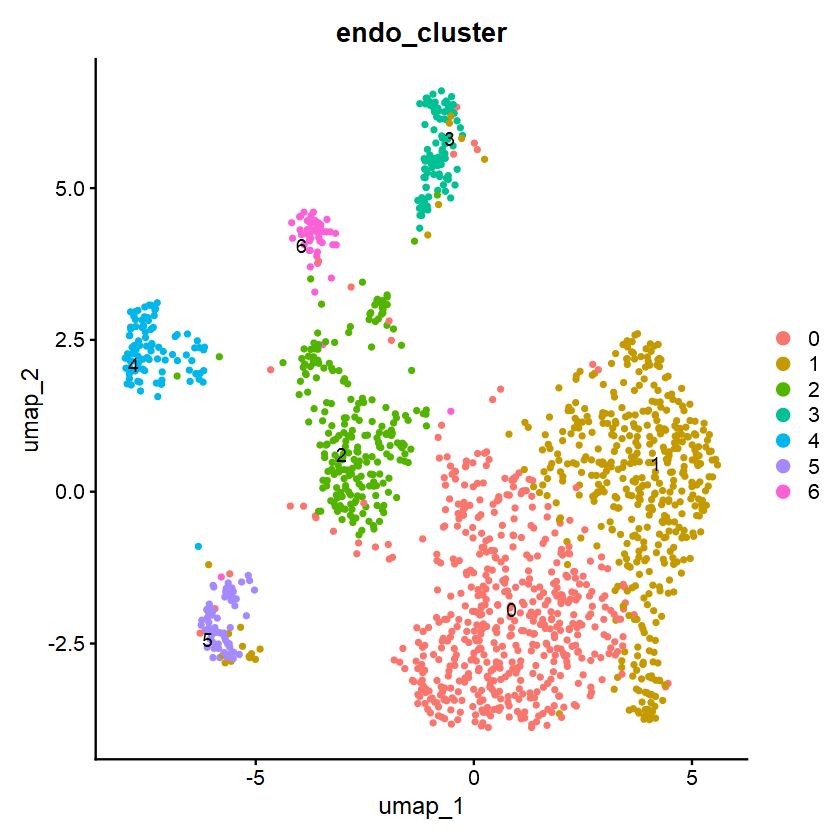

In [30]:
endo <- RunUMAP(endo, dims = 1:15, seed.use = 1234)
endo_umap <- DimPlot(
  endo, reduction = "umap",
  group.by = "endo_cluster", label = TRUE, repel = TRUE
)
show_plot(endo_umap, 9, 7)
save_plot(endo_umap, "Endothelial_candidate_clusters_UMAP", 9, 7)

## 13. Check endothelial and competing-lineage markers

The marker panels compare endothelial genes with markers from possible capillary, venous, lymphatic, stromal, myeloid and T/NK cells. The dot size is the percentage of cells expressing a gene; the colour shows average expression.

In [31]:
marker_sets <- list(
  EC_core = c("PECAM1", "CDH5", "CLDN5", "ERG", "VWF", "ESAM", "KDR", "FLT1"),
  Capillary = c("CA4", "RBP7", "GPIHBP1", "RGCC", "CD36"),
  Venous = c("ACKR1", "SELE", "VCAM1", "ICAM1"),
  Lymphatic = c("PROX1", "LYVE1", "MMRN1", "PDPN", "CCL21"),
  Stromal = c("COL1A1", "DCN", "LUM", "DPT", "FBLN1"),
  Myeloid = c("PTPRC", "LST1", "FCER1G", "CD163", "CHIT1"),
  T_NK = c("TRBC1", "CD3D", "NKG7", "GNLY")
)

marker_sets <- lapply(marker_sets, function(genes) {
  intersect(genes, rownames(endo))
})
marker_sets <- marker_sets[lengths(marker_sets) > 0]

Warning message:
"The `facets` argument of `facet_grid()` is deprecated as of ggplot2 2.2.0.
ℹ Please use the `rows` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>."


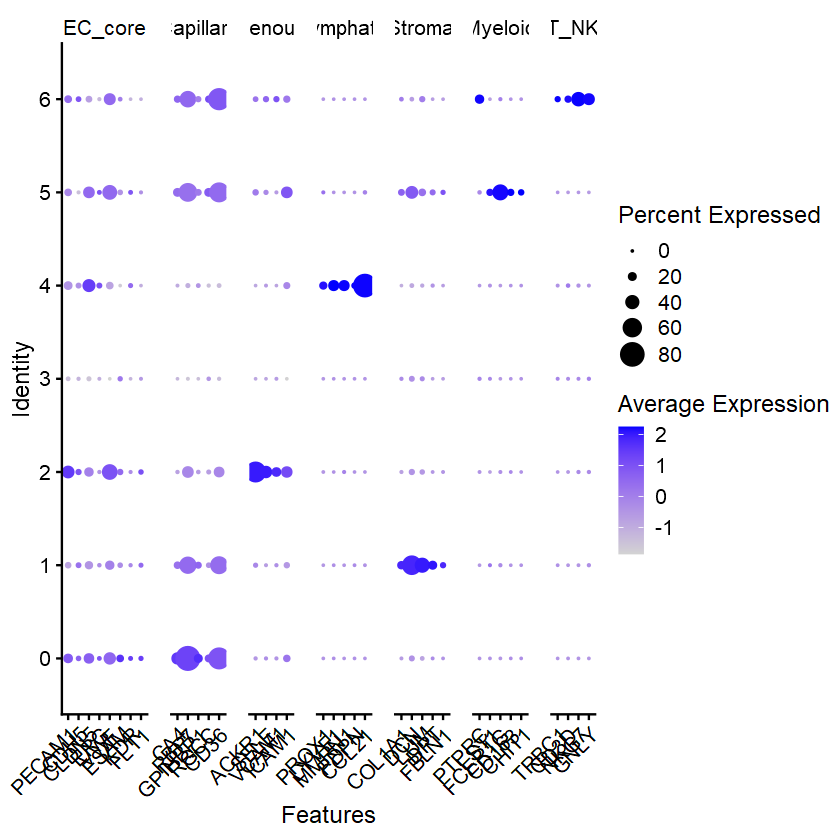

In [32]:
marker_dotplot <- DotPlot(
  endo, features = marker_sets,
  group.by = "endo_cluster"
) + RotatedAxis()
show_plot(marker_dotplot, 14, 7)
save_plot(marker_dotplot, "Endothelial_marker_dotplot", 14, 7)

### Optional marker scores

A module score is the average signal from a marker list, adjusted against control genes. It is a summary for review, not a probability that a cell has that identity.

In [33]:
for (set_name in names(marker_sets)) {
  endo <- AddModuleScore(
    endo,
    features = list(marker_sets[[set_name]]),
    name = paste0(set_name, "Score")
  )
}

score_columns <- paste0(names(marker_sets), "Score1")
print(score_columns)

[1] "EC_coreScore1"   "CapillaryScore1" "VenousScore1"    "LymphaticScore1"
[5] "StromalScore1"   "MyeloidScore1"   "T_NKScore1"     


In [34]:
cluster_scores <- endo[[]] |>
  group_by(endo_cluster) |>
  summarise(
    across(all_of(score_columns), median, na.rm = TRUE),
    .groups = "drop"
  )
print(cluster_scores)
save_table(cluster_scores, "Endothelial_cluster_marker_scores.csv")

# A tibble: 7 × 8
  endo_cluster EC_coreScore1 Capillary…¹ Venou…² Lymph…³ Strom…⁴ Myelo…⁵ T_NKS…⁶
  <chr>                <dbl>       <dbl>   <dbl>   <dbl>   <dbl>   <dbl>   <dbl>
1 0                   0.0607       1.01   -0.535  -0.104  -0.445 -0.0350 -0.0497
2 1                  -0.283        0.183  -0.580  -0.120   0.305 -0.0353 -0.0511
3 2                   0.0703      -0.409   0.572  -0.117  -0.462 -0.0400 -0.0527
4 3                  -0.342       -0.553  -0.591  -0.123  -0.447 -0.0285 -0.0423
5 4                  -0.235       -0.586  -0.628   1.01   -0.519 -0.0384 -0.0582
6 5                  -0.0421       0.303  -0.577  -0.129  -0.390  0.439  -0.0665
7 6                  -0.0275       0.725  -0.488  -0.113  -0.430 -0.0307  0.799 
# … with abbreviated variable names ¹​CapillaryScore1, ²​VenousScore1,
#   ³​LymphaticScore1, ⁴​StromalScore1, ⁵​MyeloidScore1, ⁶​T_NKScore1


## 14. Give the endothelial clusters provisional names

These are the current working interpretations from the marker plots: cluster 0 is capillary-like, cluster 2 is activated venous-like, and cluster 3 is lymphatic-like. Clusters 1, 4 and 5 have competing-lineage signals and stay in review.

In [35]:
subtype_labels <- c(
  "0" = "Capillary-like EC candidate",
  "1" = "Stromal-associated: review",
  "2" = "Activated venous-like EC candidate",
  "3" = "Lymphatic-like EC candidate",
  "4" = "Myeloid-associated: review",
  "5" = "T/NK-associated: review"
)

endo$subtype <- unname(subtype_labels[endo$endo_cluster])
print(table(endo$subtype, useNA = "ifany"))


Activated venous-like EC candidate        Capillary-like EC candidate 
                               234                                541 
       Lymphatic-like EC candidate         Myeloid-associated: review 
                                94                                 93 
        Stromal-associated: review            T/NK-associated: review 
                               466                                 66 
                              <NA> 
                                51 


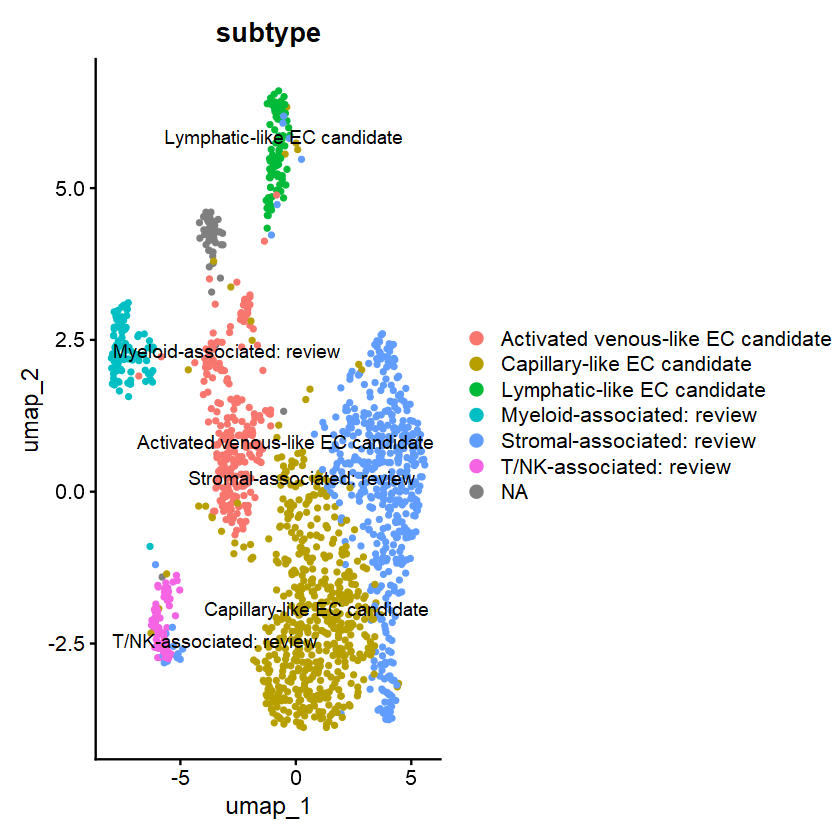

In [36]:
subtype_plot <- DimPlot(
  endo, reduction = "umap",
  group.by = "subtype", label = TRUE, repel = TRUE
)
show_plot(subtype_plot, 11, 8)
save_plot(subtype_plot, "Endothelial_provisional_subtypes_UMAP", 11, 8)

## 15. Check sample representation

Each sample is shown separately. The cell counts help identify samples with very few cells in a subgroup.

In [37]:
endo_counts_by_sample <- endo[[]] |>
  count(sample, donor, condition, tissue, endo_cluster, name = "n_cells")
print(endo_counts_by_sample)
save_table(endo_counts_by_sample, "Endothelial_cells_by_sample_and_cluster.csv")

        sample  donor condition tissue endo_cluster n_cells
1   Ate-04-SAT Ate-04   Control    SAT            0      12
2   Ate-04-SAT Ate-04   Control    SAT            1       4
3   Ate-04-SAT Ate-04   Control    SAT            2       4
4   Ate-04-SAT Ate-04   Control    SAT            3       1
5   Ate-04-VAT Ate-04   Control    VAT            0       6
6   Ate-04-VAT Ate-04   Control    VAT            1      24
7   Ate-04-VAT Ate-04   Control    VAT            2       6
8   Ate-04-VAT Ate-04   Control    VAT            3       1
9   Ate-04-VAT Ate-04   Control    VAT            4      16
10  Ate-04-VAT Ate-04   Control    VAT            5       1
11  Ate-05-SAT Ate-05       T2D    SAT            0       1
12  Ate-05-SAT Ate-05       T2D    SAT            1       9
13  Ate-05-SAT Ate-05       T2D    SAT            2       6
14  Ate-05-SAT Ate-05       T2D    SAT            3       2
15  Ate-05-SAT Ate-05       T2D    SAT            4       1
16  Ate-05-VAT Ate-05       T2D    VAT  

In [38]:
sample_cluster_table <- table(endo$sample, endo$endo_cluster)
sample_cluster_percent <- 100 * prop.table(sample_cluster_table, margin = 1)
print(round(sample_cluster_percent, 1))

            
                0    1    2    3    4    5    6
  Ate-04-SAT 57.1 19.0 19.0  4.8  0.0  0.0  0.0
  Ate-04-VAT 11.1 44.4 11.1  1.9 29.6  1.9  0.0
  Ate-05-SAT  5.3 47.4 31.6 10.5  5.3  0.0  0.0
  Ate-05-VAT 28.6 57.1  3.2  1.6  4.8  4.8  0.0
  Ate-06-SAT 43.9 39.0  4.9  2.4  4.9  1.2  3.7
  Ate-06-VAT  7.0  7.0 19.7 52.1 14.1  0.0  0.0
  Ate-08-SAT 45.1 39.4  1.4  0.0  2.8  7.0  4.2
  Ate-08-VAT 26.7 20.0  6.7  6.7 33.3  0.0  6.7
  Ate-09-SAT 21.4 59.5  9.5  0.0  0.0  9.5  0.0
  Ate-09-VAT 14.8 59.3  3.7  0.0 22.2  0.0  0.0
  Ate-10-SAT 28.6 14.3 57.1  0.0  0.0  0.0  0.0
  Ate-10_VAT 45.2 32.3  9.7  0.0 12.9  0.0  0.0
  Ate-11-SAT 62.1 13.8 24.1  0.0  0.0  0.0  0.0
  Ate-11-VAT  0.0 50.0  3.3  0.0 43.3  3.3  0.0
  Ate-12-SAT 28.6 71.4  0.0  0.0  0.0  0.0  0.0
  Ate-12-VAT 50.0 50.0  0.0  0.0  0.0  0.0  0.0
  Ate-13-SAT 64.4 21.1  7.8  2.2  0.0  1.1  3.3
  Ate-13-VAT 62.5 29.2  4.2  0.0  0.0  0.0  4.2
  Ate-14-SAT 51.4 40.5  6.8  1.4  0.0  0.0  0.0
  Ate-14-VAT 60.0 26.7 13.3

In [39]:
sample_umap <- DimPlot(
  endo, reduction = "umap",
  group.by = "sample", raster = TRUE
)
show_plot(sample_umap, 12, 8)
save_plot(sample_umap, "Endothelial_UMAP_by_sample", 12, 8)

ERROR: Error in fill_alpha(data$fill %||% "black", data$alpha): could not find function "fill_alpha"


## 16. Find marker genes for each endothelial cluster

This is a descriptive search for genes that are higher in one endothelial cluster than the others. These cell-level marker tests help name clusters; they are not the donor-level Control-versus-T2D test.

In [ ]:
Idents(endo) <- "endo_cluster"
cluster_markers <- FindAllMarkers(
  endo,
  only.pos = TRUE,
  min.pct = 0.1,
  logfc.threshold = 0.25
)

print(head(cluster_markers))
save_table(cluster_markers, "Endothelial_cluster_markers.csv")

In [ ]:
top_markers <- cluster_markers |>
  filter(!is.na(p_val_adj), p_val_adj < fdr_cutoff) |>
  group_by(cluster) |>
  slice_max(avg_log2FC, n = 10, with_ties = FALSE) |>
  ungroup()

print(top_markers)
save_table(top_markers, "Endothelial_top10_markers.csv")

## 17. Compare endothelial subgroup proportions

The plot shows the percentage of candidate endothelial cells in each subgroup for every sample. These are descriptive percentages; this notebook does not yet run a formal statistical test of subgroup abundance.

In [ ]:
# Use clusters 0, 2 and 3 as the current endothelial candidates.
ec_clusters <- c("0", "2", "3")
ec_cells <- colnames(endo)[endo$endo_cluster %in% ec_clusters]
ec <- subset(endo, cells = ec_cells)

sample_subgroup_counts <- table(
  ec$sample,
  factor(ec$endo_cluster, levels = ec_clusters)
)
subgroup_percent <- 100 * prop.table(sample_subgroup_counts, margin = 1)
print(round(subgroup_percent, 1))

In [ ]:
subgroup_table <- as.data.frame(sample_subgroup_counts)
colnames(subgroup_table) <- c("sample", "endo_cluster", "n_cells")

sample_info <- ec[[]] |>
  distinct(sample, donor, condition, tissue)
subgroup_table <- left_join(subgroup_table, sample_info, by = "sample")

subgroup_table <- subgroup_table |>
  group_by(sample) |>
  mutate(percent = 100 * n_cells / sum(n_cells)) |>
  ungroup()

save_table(subgroup_table, "Endothelial_subgroup_percentages.csv")

In [ ]:
subgroup_plot <- ggplot(
  subgroup_table,
  aes(x = condition, y = percent, colour = condition)
) +
  geom_boxplot(outlier.shape = NA, alpha = 0.15) +
  geom_point(position = position_jitter(width = 0.1, seed = 1234)) +
  facet_grid(tissue ~ endo_cluster) +
  scale_colour_manual(values = c(Control = "#377EB8", T2D = "#E45756")) +
  labs(x = NULL, y = "Percent of candidate endothelial cells") +
  theme_classic() +
  theme(legend.position = "none")

show_plot(subgroup_plot, 14, 7)
save_plot(subgroup_plot, "Endothelial_subgroup_percentages", 14, 7)

## 18. Read only the target genes from the normalized SVF matrix

The normalized file is very large. The next cells read it one row at a time and keep only the eight target genes and the selected endothelial cells. This avoids loading the whole dense matrix into memory.

In [ ]:
# Use candidate endothelial cells for these expression plots.
plot_cells <- subset(endo, cells = ec_cells)
target_cells <- colnames(plot_cells)

svf_connection <- open_text_file(normalized_file)
svf_header <- strsplit(
  readLines(svf_connection, n = 1, warn = FALSE),
  "\\t", fixed = TRUE
)[[1]]

# Remove the first field if it is not a barcode (the file has a blank field).
if (!(svf_header[1] %in% barcodes)) {
  svf_header <- svf_header[-1]
}

In [ ]:
# Find where our selected barcodes sit among all SVF matrix columns.
cell_positions <- match(target_cells, svf_header)
matched_cells <- target_cells[!is.na(cell_positions)]
cell_positions <- cell_positions[!is.na(cell_positions)]

if (length(matched_cells) == 0) {
  stop("No selected cell barcodes matched the normalized SVF matrix.")
}

cat("Matched cells:", length(matched_cells), "of", length(target_cells), "\n")

In [ ]:
# Start an empty table for the target-gene values.
target_matrix <- matrix(
  NA_real_,
  nrow = length(focus_genes),
  ncol = length(matched_cells),
  dimnames = list(focus_genes, matched_cells)
)

In [ ]:
# Read one gene row at a time and keep only the eight requested genes.
while (TRUE) {
  line <- readLines(svf_connection, n = 1, warn = FALSE)
  if (length(line) == 0) break

  fields <- strsplit(line, "\\t", fixed = TRUE)[[1]]
  gene_name <- fields[1]

  if (gene_name %in% focus_genes &&
      length(fields) >= max(cell_positions) + 1) {
    target_matrix[gene_name, matched_cells] <- suppressWarnings(
      as.numeric(fields[cell_positions + 1])
    )
  }
}

close(svf_connection)

In [ ]:
genes_found <- rownames(target_matrix)[
  rowSums(!is.na(target_matrix)) > 0
]

if (length(genes_found) == 0) {
  stop("No target genes were read. Check the normalized file format.")
}

cat("Genes found:", paste(genes_found, collapse = ", "), "\n")

## 19. Make the sample-wise target-gene plots

Each violin shows the cells from one sample. SAT and VAT appear in separate panels. The black point marks the median expression in that sample.

In [ ]:
target_wide <- as.data.frame(
  t(target_matrix[genes_found, , drop = FALSE]),
  check.names = FALSE
)
target_wide$cell <- rownames(target_wide)

cell_metadata <- plot_cells[[]]
cell_metadata$cell <- rownames(cell_metadata)
cell_metadata <- cell_metadata |>
  select(cell, sample, donor, condition, tissue)

target_wide <- left_join(target_wide, cell_metadata, by = "cell")

In [ ]:
target_long <- target_wide |>
  pivot_longer(
    cols = all_of(genes_found),
    names_to = "gene",
    values_to = "expression"
  )

target_long$condition <- factor(target_long$condition, levels = c("Control", "T2D"))
target_long$tissue <- factor(target_long$tissue, levels = c("SAT", "VAT"))

sample_means <- target_long |>
  group_by(gene, sample, donor, condition, tissue) |>
  summarise(mean_expression = mean(expression, na.rm = TRUE), .groups = "drop")

print(filter(sample_means, gene == "ERG"))
save_table(sample_means, "Target_gene_sample_means.csv", "DE")

In [ ]:
erg_plot <- ggplot(
  filter(target_long, gene == "ERG"),
  aes(x = sample, y = expression, fill = condition)
) +
  geom_violin(trim = TRUE, scale = "width", na.rm = TRUE) +
  stat_summary(fun = median, geom = "point", size = 1.5) +
  facet_wrap(~ tissue, scales = "free_x") +
  scale_fill_manual(values = c(Control = "#377EB8", T2D = "#E45756")) +
  labs(
    title = "ERG expression in candidate endothelial cells",
    x = "Sample", y = "Normalized expression", fill = "Group"
  ) +
  theme_classic() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

show_plot(erg_plot, 13, 6)
save_plot(erg_plot, "ERG_samplewise_expression", 13, 6)

In [ ]:
target_plot <- ggplot(
  target_long,
  aes(x = sample, y = expression, fill = condition)
) +
  geom_violin(trim = TRUE, scale = "width", na.rm = TRUE) +
  stat_summary(fun = median, geom = "point", size = 0.8) +
  facet_grid(gene ~ tissue, scales = "free_x", space = "free_x") +
  scale_fill_manual(values = c(Control = "#377EB8", T2D = "#E45756")) +
  labs(x = "Sample", y = "Normalized expression", fill = "Group") +
  theme_classic() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1, size = 7))

show_plot(target_plot, 15, 13)
save_plot(target_plot, "Eight_target_genes_samplewise", 15, 13)

## 20. Compare Control and T2D with pseudobulk

Pseudobulk adds raw counts from cells belonging to the same sample. The donor/sample—not each individual cell—is the replicate in the disease comparison. SAT and VAT are tested separately. The minimum is five cells per sample and at least three donors per condition.

In [ ]:
# Choose the cell groups to compare.
cluster_id <- endo$endo_cluster
populations <- list(
  All_EC = colnames(endo)[cluster_id %in% c("0", "2", "3")],
  Blood_vessel_EC = colnames(endo)[cluster_id %in% c("0", "2")],
  Capillary_EC = colnames(endo)[cluster_id == "0"],
  Venous_EC = colnames(endo)[cluster_id == "2"],
  Lymphatic_EC = colnames(endo)[cluster_id == "3"]
)

print(sapply(populations, length))

### Helper: add raw counts within each sample

This function creates one pseudobulk count column per sample. Samples with fewer than five cells in the selected group are left out.

In [ ]:
make_pseudobulk <- function(cell_ids) {
  small_object <- subset(endo, cells = cell_ids)
  cell_numbers <- table(small_object$sample)
  keep_samples <- names(cell_numbers[cell_numbers >= min_cells_per_sample])

  if (length(keep_samples) == 0) return(NULL)

  keep_cells <- colnames(small_object)[small_object$sample %in% keep_samples]
  small_object <- subset(small_object, cells = keep_cells)

  # AggregateExpression sums the raw RNA counts by sample.
  summed_counts <- AggregateExpression(
    small_object,
    assays = "RNA",
    group.by = "sample",
    return.seurat = FALSE
  )$RNA

  sample_data <- small_object[[]] |>
    distinct(sample, donor, condition, tissue, batch)
  sample_data$n_cells <- as.integer(cell_numbers[sample_data$sample])
  sample_data <- sample_data[match(colnames(summed_counts), sample_data$sample), ]

  list(counts = summed_counts, samples = sample_data)
}

### Helper: test one tissue

This function fits the Control-versus-T2D model for either SAT or VAT. The model uses condition only; clinical covariate adjustment is a later step.

In [ ]:
test_one_tissue <- function(pseudobulk, tissue_name) {
  sample_data <- pseudobulk$samples |>
    filter(tissue == tissue_name)

  donor_numbers <- sample_data |>
    distinct(donor, condition) |>
    count(condition)

  if (nrow(donor_numbers) < 2 || any(donor_numbers$n < min_donors_per_group)) {
    return(list(status = "Skipped", reason = "Fewer than 3 donors in a group."))
  }

  sample_data$condition <- factor(
    sample_data$condition,
    levels = c("Control", "T2D")
  )
  counts_for_tissue <- pseudobulk$counts[, sample_data$sample, drop = FALSE]
  design <- model.matrix(~ condition, data = sample_data)

  y <- DGEList(counts = counts_for_tissue)
  keep_genes <- filterByExpr(y, design = design)
  y <- y[keep_genes, , keep.lib.sizes = FALSE]
  y <- calcNormFactors(y, method = "TMM")

  voom_data <- voom(y, design, plot = FALSE)
  fit <- lmFit(voom_data, design)
  fit <- eBayes(fit)
  all_genes <- topTable(fit, coef = "conditionT2D", number = Inf)

  all_genes$gene <- rownames(all_genes)
  target_results <- all_genes |>
    filter(gene %in% focus_genes) |>
    select(gene, logFC, P.Value, adj.P.Val)

  list(status = "Complete", reason = "", results = target_results,
       donor_numbers = donor_numbers)
}

### Run the target-gene comparisons

The loop repeats the same analysis for each endothelial group and for SAT and VAT separately. Only the eight target genes are saved in the result table; adjusted p-values are calculated across all genes tested in each comparison.

In [ ]:
target_de_tables <- list()
comparison_status <- list()

for (population_name in names(populations)) {
  message("Processing: ", population_name)
  pseudobulk <- make_pseudobulk(populations[[population_name]])

  for (tissue_name in c("SAT", "VAT")) {
    comparison_name <- paste(population_name, tissue_name, sep = "__")

    if (is.null(pseudobulk)) {
      result <- list(status = "Skipped", reason = "No samples met the cell minimum.")
    } else {
      result <- test_one_tissue(pseudobulk, tissue_name)
    }

    comparison_status[[comparison_name]] <- data.frame(
      population = population_name,
      tissue = tissue_name,
      status = result$status,
      reason = result$reason
    )

    if (result$status == "Complete") {
      table <- result$results
      table$population <- population_name
      table$tissue <- tissue_name
      target_de_tables[[comparison_name]] <- table
    }
  }
}

In [ ]:
status_table <- bind_rows(comparison_status)
print(status_table)
save_table(status_table, "Pseudobulk_comparison_status.csv", "DE")

if (length(target_de_tables) > 0) {
  target_de_results <- bind_rows(target_de_tables) |>
    select(population, tissue, gene, logFC, P.Value, adj.P.Val)

  print(target_de_results)
  save_table(target_de_results, "Eight_target_genes_pseudobulk_DE.csv", "DE")
} else {
  message("No comparisons had enough donors for testing.")
}

## 21. How to read the pseudobulk results

- `logFC` is the estimated log2 fold change for T2D compared with Control. Positive values indicate higher expression in T2D.
- `P.Value` is the unadjusted p-value.
- `adj.P.Val` is the false-discovery-rate adjusted p-value across all genes tested in that comparison.
- A violin plot shows cell-level expression distributions. It does not replace the donor-level pseudobulk test.
- A skipped comparison means the donor minimum was not met; it is not evidence of no difference.

## 22. Save the analysis objects

These files let you continue the analysis without rebuilding the Seurat objects.

In [ ]:
saveRDS(obj, file.path(results_dir, "annotated_cells.rds"))
saveRDS(endo, file.path(results_dir, "endothelial_candidates.rds"))
writeLines(capture.output(sessionInfo()), file.path(results_dir, "sessionInfo.txt"))

cat("Results saved in:", results_dir, "\n")

## What this notebook has and has not done

This notebook analyzes author-annotated GSE129363 cells, reviews QC measurements, reclusters endothelial candidates, plots normalized SVF expression for eight genes, and tests those genes with donor-level pseudobulk separately in SAT and VAT.

The endothelial subtype labels are provisional. The notebook does not yet repeat cell calling, run a full doublet or ambient-RNA workflow, adjust for age/sex/BMI/batch, formally test cell-subgroup proportions, analyze the other proposed datasets, or run pathway and independent-replication analyses. The Control group is the study's non-diabetic comparison group; it should not be described as lean healthy controls.